ImPort libraries

In [ ]:
from langgraph.graph import START,END,StateGraph
from typing import TypedDict

Defining The State

In [ ]:
class TempConvert(TypedDict):
    temp_celsius: float
    temp_fahrenheit: float
    weather_status: str
    

Define and compile Graph

In [ ]:
#cretae a function for  temp_convert
def temp_convert(state: TempConvert) -> TempConvert:
    temp_celcius=state['temp_celsius']
    farenheit=(temp_celcius*9/5)+32
    state['temp_fahrenheit']=round(farenheit, 2)
    return state


In [ ]:
#weather status function
def weather_status(state: TempConvert) -> TempConvert:
    temp_celcius=state['temp_celsius']
    if temp_celcius<0:
        state['weather_status']='Freezing'
    elif temp_celcius<10:
        state['weather_status']='Cold'
    elif temp_celcius<20:
        state['weather_status']='Cool'
    elif temp_celcius<30:
        state['weather_status']='Warm'
    else:
        state['weather_status']='Hot'
    return state

In [ ]:
#defining the graph
graph=StateGraph(TempConvert)
#add nodes to the graph
graph.add_node('temp_convert',temp_convert)
graph.add_node('weather_status',weather_status)

In [ ]:
#add edges to the graph
graph.add_edge(START,'temp_convert')
graph.add_edge('temp_convert','weather_status')
graph.add_edge('weather_status',END)

#now compile the graph
workflow=graph.compile()

In [ ]:
#now execute the graph with a sample input
intial_state={'temp_celsius': 37.0}
final_state=workflow.invoke(intial_state)
print(final_state)

{'temp_celsius': 37.0, 'temp_fahrenheit': 98.6, 'weather_status': 'Hot'}


Vizualization of the graph can be done using the following code:

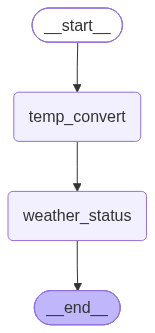

In [ ]:
from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())